In [1]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

print("XGBoost & Machine Learning Pipeline Active.")

# --- REUSABLE PIPELINE SIMULATION ---
# Simulate 1,000 pipeline corridor segments with morphodynamic & hydrodynamic predictors
np.random.seed(42)
n_samples = 1000

data = pd.DataFrame({
    'current_speed_ms': np.random.uniform(0.1, 1.8, n_samples),      # From Copernicus / ADCP
    'slope_deg': np.random.uniform(0.0, 15.0, n_samples),            # From MBES bathymetry
    'roughness_sri': np.random.uniform(0.01, 0.5, n_samples),        # Seabed Roughness Index
    'bcr_myr': np.random.normal(-0.05, 0.25, n_samples),             # Bathymetric Change Rate (negative = scour)
    'burial_depth_m': np.random.uniform(-0.5, 2.0, n_samples)        # From SBP / Magnetometer (negative = exposed/free-span)
})

# Define synthetic vulnerability target (1 = High Free-Span Hazard, 0 = Stable)
# Higher risk when current speed is high, scour (negative BCR) is active, and burial depth is shallow/exposed
risk_score = (
    1.5 * data['current_speed_ms'] 
    + 0.12 * data['slope_deg'] 
    - 2.0 * data['bcr_myr'] 
    - 1.2 * data['burial_depth_m'] 
    + np.random.normal(0, 0.4, n_samples)
)
data['high_vulnerability'] = (risk_score > np.percentile(risk_score, 70)).astype(int)

# 1. Split features (X) and target (y)
X = data.drop(columns=['high_vulnerability'])
y = data['high_vulnerability']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 2. Initialize and train the XGBoost Classifier
model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
model.fit(X_train, y_train)

# 3. Evaluate Model Performance
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # Continuous Morphodynamic Vulnerability Index (0 to 1)

print(f"\nModel Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC Score:  {roc_auc_score(y_test, y_prob):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 4. Save trained model weights to your 06_models tier
home_path = os.path.expanduser("~")
model_dir = os.path.join(home_path, "niger-delta-phd", "06_models")
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "xgboost_mvi_template.json")
model.save_model(model_path)
print(f"Trained model safely saved to: {model_path}")


XGBoost & Machine Learning Pipeline Active.

Model Accuracy: 0.916
ROC-AUC Score:  0.978

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       175
           1       0.86      0.87      0.86        75

    accuracy                           0.92       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.92      0.92      0.92       250

Trained model safely saved to: /Users/macbookpro2020/niger-delta-phd/06_models/xgboost_mvi_template.json


/var/folders/z0/31zbys_d55j5gp3w6nyl9p140000gn/T/ipykernel_85951/3215055752.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


SHAP Summary Plot saved to: /Users/macbookpro2020/niger-delta-phd/07_figures/05_shap_mvi_importance.png


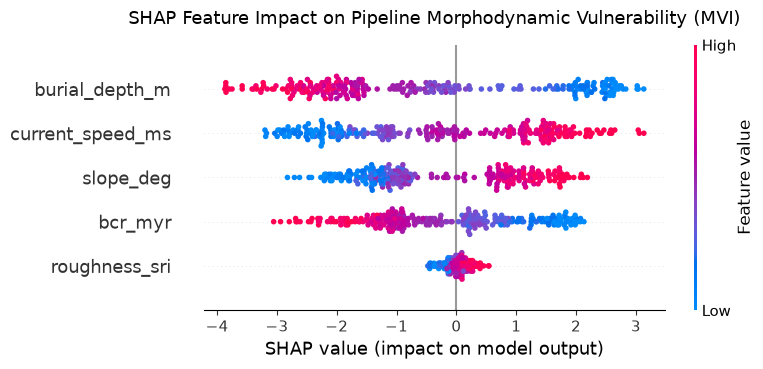

In [2]:
import shap
import matplotlib.pyplot as plt

# 1. Compute SHAP values for the test dataset
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# 2. Generate SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Feature Impact on Pipeline Morphodynamic Vulnerability (MVI)", fontsize=13, pad=15)

# 3. Save publication-grade figure to 07_figures tier
fig_path = os.path.join(home_path, "niger-delta-phd", "07_figures", "05_shap_mvi_importance.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"SHAP Summary Plot saved to: {fig_path}")

plt.show()
